In [1]:
n=19
g=1.2
mu=2.5
T=50
import numpy as np
import scipy
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from scipy.optimize import root

In [ ]:
def part1q1a(n, g, mu, T):
    """Part 1, question 1 (a)
    Use the variable inputs if/as needed.
    Input:
    n: number of ODEs
    g,mu: model parameters
    T: time at which perturbation energy ratio should be maximized

    Output:
    xbar: n-element array containing non-trivial equilibrium solution
    xtilde0: n-element array corresponding to computed initial condition
    eratio: computed maximum perturbation energy ratio
    """
    xbar = np.zeros(n)
    xtilde0 = np.zeros(n)
    eratio = 0.0

    def model(X, n, g, mu):
        dXdt = np.zeros(n)
        dXdt[0] = X[0] * (1 - g * X[-2] - X[0] - g * X[1] + mu * X[-3])
        dXdt[1] = X[1] * (1 - g * X[-1] - X[1] - g * X[2])
        dXdt[2 : n - 1] = X[2 : n - 1] * (
            1 - g * X[0 : n - 3] - X[2 : n - 1] - g * X[3:n]
        )
        dXdt[-1] = X[-1] * (1 - g * X[-3] - X[-1] - g * X[0])
        return dXdt

    eventus = root(
        model,
        1 / (2 * g + 1) + 0.1 * np.random.rand(n),
        method="krylov",
        args=(n, g, mu),
    )
    x_bar = eventus.x

    B = np.zeros([n, n])
    for i in range(2, n - 1):
        B[i, i] = -1
        B[i, i - 2] = -g
        B[i, i + 1] = -g

    B[0, 0] = -1
    B[0, n - 2] = -g
    B[0, 1] = -g
    B[0, n - 3] = mu

    B[1, 1] = -1
    B[1, n - 1] = -g
    B[1, 2] = -g

    B[n - 1, n - 1] = -1
    B[n - 1, n - 3] = -g
    B[n - 1, 0] = -g

    M = np.zeros([n, n])

    for i in range(n):
        M[i, i] = 1 + np.matmul(B[i, :], x_bar)

    for i in range(n):
        for j in range(n):
            M[i, j] += B[i, j] * x_bar[i]

    matM = scipy.linalg.expm(M * T)

    U, Sigma, VT = np.linalg.svd(matM)

    eratio = Sigma[0] ** 2

    xtilde0 = VT[0, :]

    xbar = x_bar

    return xbar, xtilde0, eratio

In [4]:
def simulate1(n, X0=-1, Nt=2000, tf=1000, g=1.0, mu=0.0, flag_display=False):
    """
    Simulation code for part 1
    Input:
        n: number of ODEs
        X0: initial condition if n-element numpy array. If X0 is an integer, the code will set
        the initial condition (otherwise an array is expected).
        Nt: number of time steps
        tf: final time
        g,mu: model parameters
        flag_display: will generate a contour plot displaying results if True
    Output:
    t,x: numpy arrays containing times and simulation results
    """

    def model(t, X, n, g, mu):
        """
        Defines the system of ODEs

        Input:
        - t: time
        - X: array of variables [x_0, x_1, ..., x_{n-1}]
        - g, mu: scalar model parameters
        - n: number of ODEs (size of the system)

        Returns:
        - dXdt: array of derivatives [dx_0/dt, dx_1/dt, ..., dx_{n-1}/dt]
        """
        dXdt = np.zeros(n)
        dXdt[0] = X[0] * (1 - g * X[-2] - X[0] - g * X[1] + mu * X[-3])
        dXdt[1] = X[1] * (1 - g * X[-1] - X[1] - g * X[2])
        dXdt[2 : n - 1] = X[2 : n - 1] * (
            1 - g * X[0 : n - 3] - X[2 : n - 1] - g * X[3:n]
        )
        dXdt[-1] = X[-1] * (1 - g * X[-3] - X[-1] - g * X[0])
        return dXdt

    # Parameters
    t_span = (0, tf)  # Time span for the integration
    if type(X0) == int:  # (modified from original version)
        X0 = 1 / (2 * g + 1) + 0.001 * np.random.rand(
            n
        )  # Random initial conditions, modify if needed

    # Solve the system
    solution = solve_ivp(
        fun=model,
        t_span=t_span,
        y0=X0,
        args=(n, g, mu),
        method="BDF",
        rtol=1e-10,
        atol=1e-10,
        t_eval=np.linspace(t_span[0], t_span[1], Nt),  # Times to evaluate the solution
    )

    t, x = (
        solution.t,
        solution.y,
    )  # (in original version of code this line was inside if-block below)
    if flag_display:
        # Plot the solution
        plt.contour(t, np.arange(n), x, 20)
        plt.xlabel("t")  # (corrected axis labels)
        plt.ylabel("i")
    return t, x

Linear analysis predicted energy ratio: 26880.0505
Simulation computed energy ratio: 26394.1659


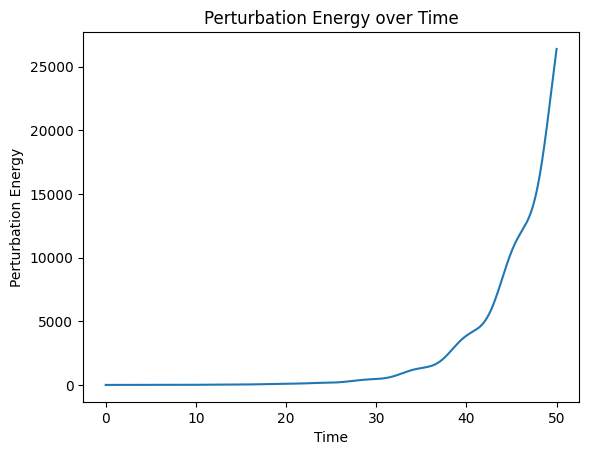

In [16]:
# Set parameters for the test
n = 19  
g = 1.2 
mu = 2.5  
T = 50  

# Results from 1q1a
xbar, xtilde0, eratio_linear= part1q1a(n, g, mu, T)

# Results from simulate1
t, x = simulate1(n=n, X0=xbar+(1e-5)*xtilde0.real, tf=T, g=g, mu=mu, flag_display=False)

perturbatio = x - xbar[:, None]  
e_t0 = np.sum(perturbatio[:, 0] ** 2)  
e_tT = np.sum(perturbatio[:, -1] ** 2)  
eratio_simulation = e_tT / e_t0  

# Compare results
print(f"Linear analysis predicted energy ratio: {eratio_linear:.4f}")
print(f"Simulation computed energy ratio: {eratio_simulation:.4f}")

# Optional: Plot perturbation energy over time
e_over_time = np.sum(perturbatio**2, axis=0)/e_t0 # Energy at each time step
plt.plot(t, e_over_time)
plt.xlabel("Time")
plt.ylabel("Perturbation Energy")
plt.title("Perturbation Energy over Time")
plt.show()

In [1]:
def part1q2():
    """Part 1, question 2:
    Add input/output if/as needed.
    """

    # add code here
    from scipy.signal import welch

    def analyze_case(n, g, mu, Nt, tf):
        """
        Analyzes a single case and produces plots and statistics.
        """
        X0 = -1
        # t, X = simulate1(n=n, X0=X0, tf=T, g=g, mu=mu, flag_display=True)
        t, X = simulate1(n=n, X0=X0, tf=T, g=g, mu=mu, flag_display=False)
        # Discard the transient (e.g., first 10% of time)
        transient_cutoff = int(0.1 * len(t))
        t = t[transient_cutoff:]
        X = X[:, transient_cutoff:]

        # Split the figures for better visualization
        num_figures = (n + 19) // 20  # Divide trajectories into groups of 20
        for fig_idx in range(num_figures):
            plt.figure(figsize=(12, 6))
            start_idx = fig_idx * 20
            end_idx = min(start_idx + 20, n)
            for i in range(start_idx, end_idx):
                plt.plot(t, X[i], label=f"x_{i}")
            plt.xlabel("Time")
            plt.ylabel("x values")
            plt.title(f"Time Evolution for n={n}, g={g}, mu={mu}, Group {fig_idx + 1}")
            plt.grid(True)
            # plt.legend()
            plt.show()

        # Compute and Plot PSD for all trajectories on one figure
        fs = 1 / (t[1] - t[0])  # Sampling frequency
        plt.figure(figsize=(8, 6))  # Single figure for all PSDs

        for i in range(n):
            freqs, psd = welch(X[i], fs=fs, nperseg=256)  # Welch method
            plt.semilogy(freqs, psd, label=f"x_{i}")

        # Add labels, legend, and grid to the single plot
        plt.xlabel("Frequency (Hz)")
        plt.ylabel("Power Spectral Density")
        plt.title(f"Power Spectral Density for all trajectories (n={n})")
        plt.grid(True)
        # plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')  # Legend outside the plot
        plt.tight_layout()  # Adjust layout to accommodate the legend
        plt.show()

        return t, X

    g = 1  # gamma
    mu = 0  # mu

    # Case A: n = 9
    print("Analyzing Case A: n = 9")
    t_A, X_A = analyze_case(n=9, g=g, mu=mu, Nt=1000, tf=500)

    # Case B: n = 20
    print("Analyzing Case B: n = 20")
    t_B, X_B = analyze_case(n=20, g=g, mu=mu, Nt=2000, tf=800)

    # Case C: n = 59
    print("Analyzing Case C: n = 59")
    t_C, X_C = analyze_case(n=59, g=g, mu=mu, Nt=3000, tf=1000)

    # Return results for further analysis
    return (t_A, X_A), (t_B, X_B), (t_C, X_C)

In [6]:
n = 9
g = 1
mu = 0
T = 50
import numpy as np
import scipy
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from scipy.optimize import root

Analyzing Case A: n = 9


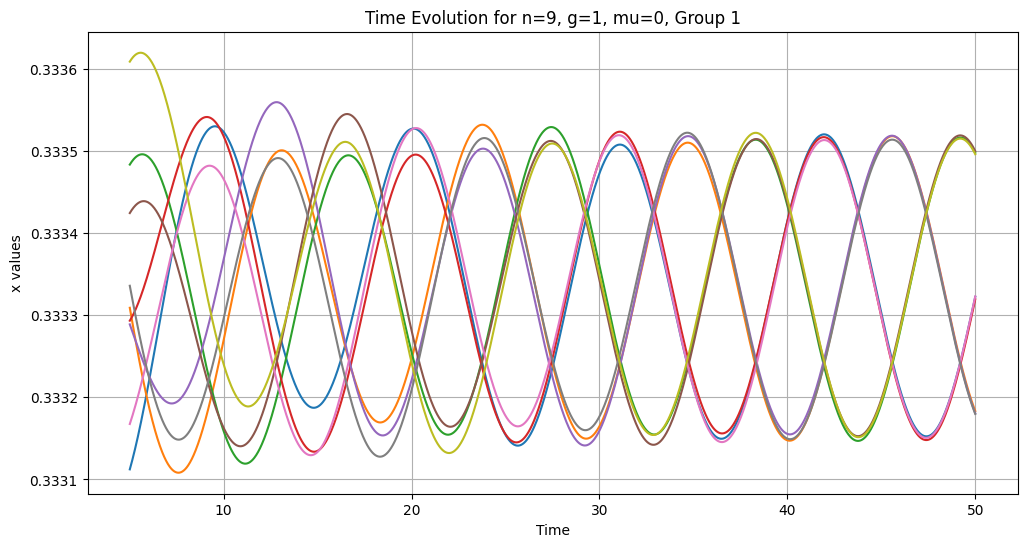

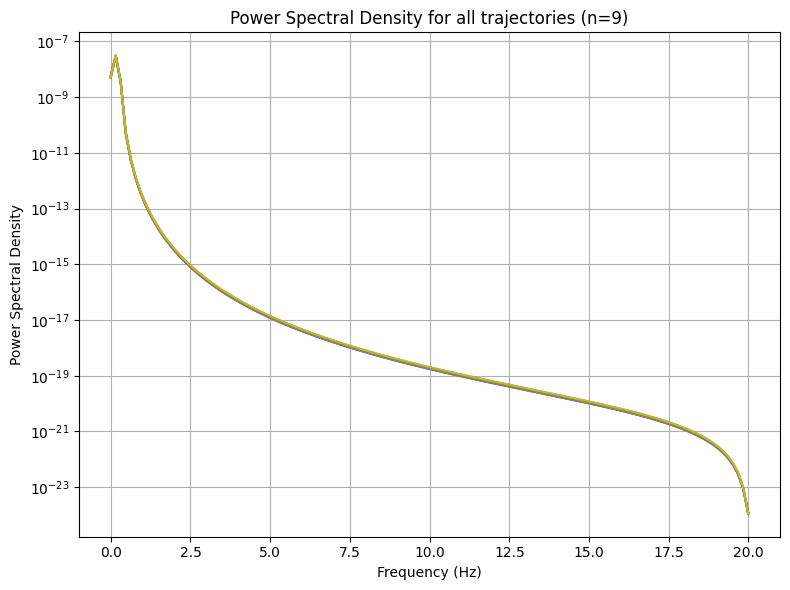

Analyzing Case B: n = 20


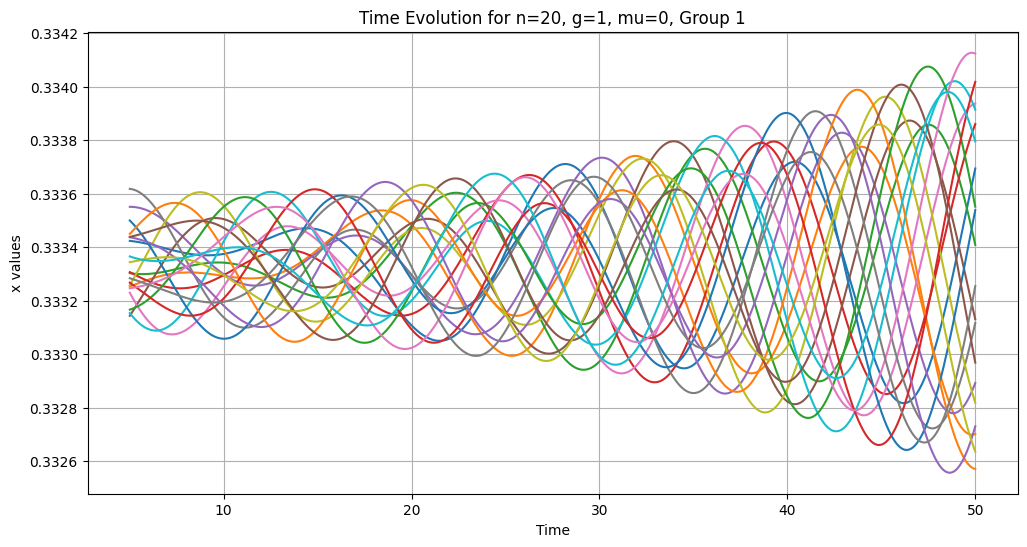

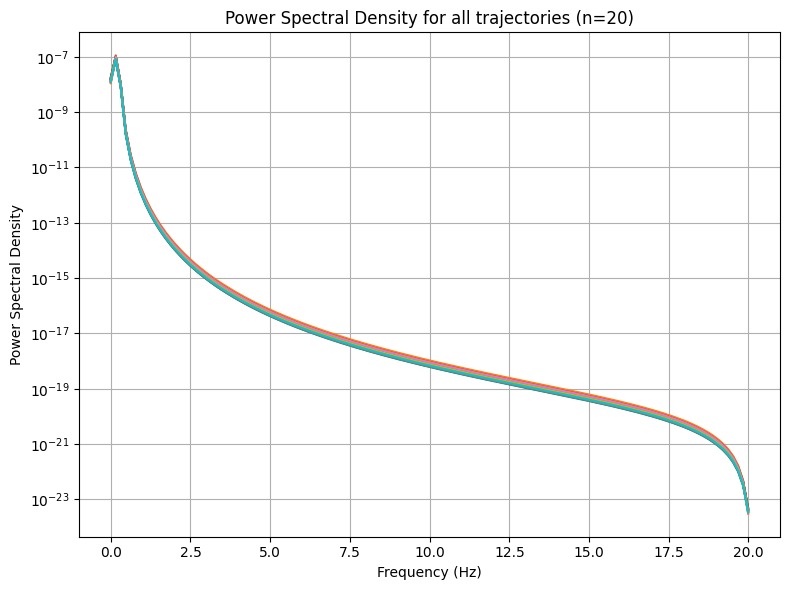

Analyzing Case C: n = 59


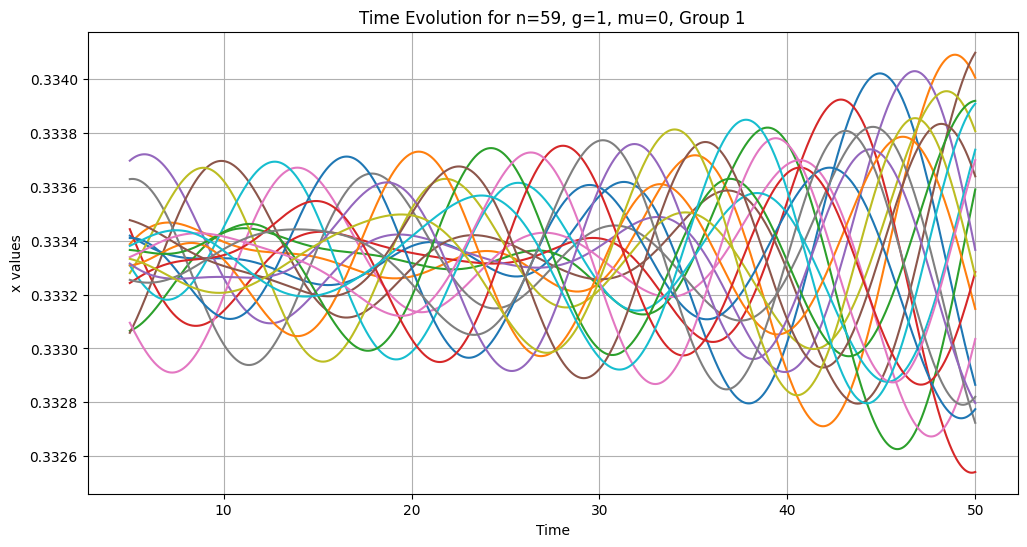

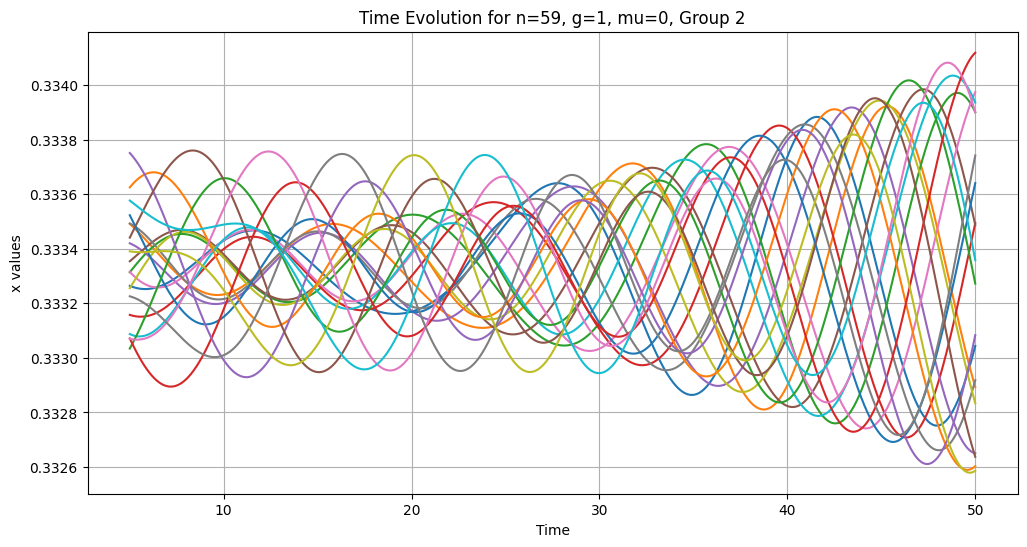

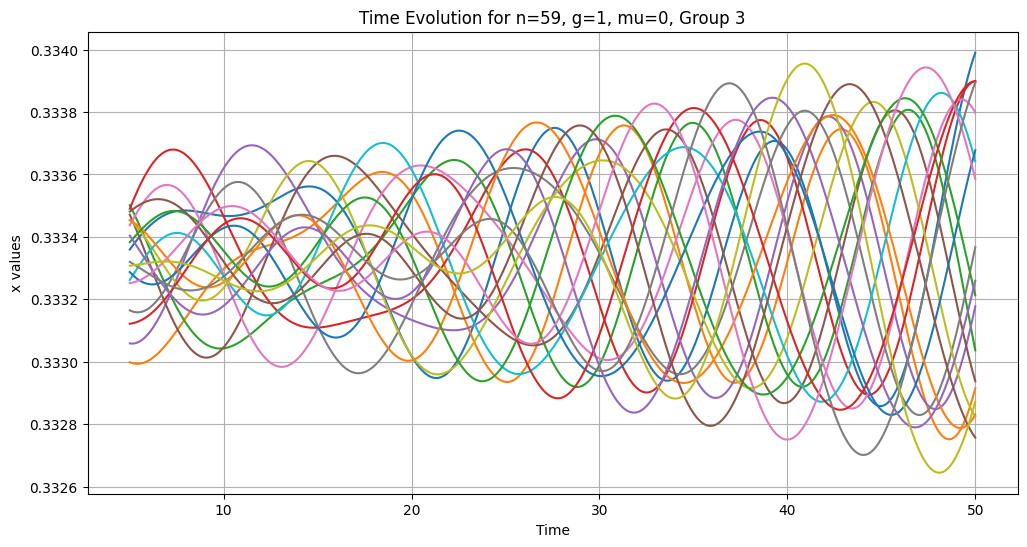

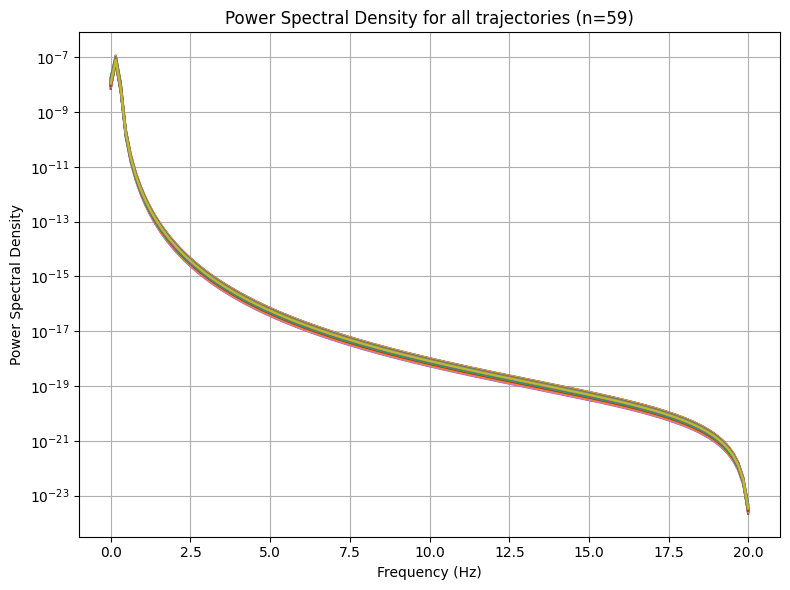

((array([ 5.00250125,  5.02751376,  5.05252626, ..., 49.94997499,
         49.97498749, 50.        ]),
  array([[0.33311221, 0.33311425, 0.33311634, ..., 0.33331688, 0.3333195 ,
          0.33332213],
         [0.33330883, 0.3333055 , 0.33330219, ..., 0.33318621, 0.3331847 ,
          0.33318321],
         [0.33348309, 0.333484  , 0.33348488, ..., 0.33349973, 0.33349863,
          0.33349749],
         ...,
         [0.33316741, 0.33316916, 0.33317093, ..., 0.33331736, 0.33332   ,
          0.33332265],
         [0.33333562, 0.33333256, 0.33332951, ..., 0.33318266, 0.33318115,
          0.33317968],
         [0.33360837, 0.33360928, 0.33361016, ..., 0.33349802, 0.3334969 ,
          0.33349574]])),
 (array([ 5.00250125,  5.02751376,  5.05252626, ..., 49.94997499,
         49.97498749, 50.        ]),
  array([[0.33342392, 0.33342373, 0.33342354, ..., 0.33367816, 0.33368628,
          0.33369437],
         [0.33325384, 0.33325448, 0.33325513, ..., 0.33270052, 0.33270113,
          0.3327

In [7]:
part1q2()